In [211]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [212]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [213]:
df = pd.read_csv('/content/drive/MyDrive/CSE475/cinema_hall_ticket_sales (2).csv')
df

,Ticket_ID,Age,Ticket_Price,Movie_Genre,Seat_Type,Number_of_Person,Purchase_Again
0,N4369,55,12.27,Comedy,Standard,7,No
1,B8091,35,19.02,Drama,Standard,Alone,Yes
2,V6341,55,22.52,Horror,VIP,3,No
3,B3243,53,23.01,Drama,Standard,6,Yes
4,I3814,30,21.81,Comedy,VIP,4,Yes
...,...,...,...,...,...,...,...
1435,E5406,41,17.09,Sci-Fi,Standard,2,Yes
1436,C4357,19,11.45,Action,Standard,Alone,No
1437,R7285,53,17.13,Comedy,Premium,Alone,Yes
1438,W6360,34,20.25,Comedy,Premium,2,Yes


In [214]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Ticket_ID         1440 non-null   object 
 1   Age               1440 non-null   int64  
 2   Ticket_Price      1440 non-null   float64
 3   Movie_Genre       1440 non-null   object 
 4   Seat_Type         1440 non-null   object 
 5   Number_of_Person  1440 non-null   object 
 6   Purchase_Again    1440 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 78.9+ KB


In [215]:
df_copy = df.copy()

In [216]:
duplicate = df[df.duplicated()]
duplicate.count()

,0
Ticket_ID,0
Age,0
Ticket_Price,0
Movie_Genre,0
Seat_Type,0
Number_of_Person,0
Purchase_Again,0


In [217]:
df.isnull().sum()

,0
Ticket_ID,0
Age,0
Ticket_Price,0
Movie_Genre,0
Seat_Type,0
Number_of_Person,0
Purchase_Again,0


In [218]:
# Display the first and last 15 rows
print("First 15 rows:")
print(df.head(15))
print("\nLast 15 rows:")
print(df.tail(15))

First 15 rows:
   Ticket_ID  Age  Ticket_Price Movie_Genre Seat_Type Number_of_Person  \
0      N4369   55         12.27      Comedy  Standard                7   
1      B8091   35         19.02       Drama  Standard            Alone   
2      V6341   55         22.52      Horror       VIP                3   
3      B3243   53         23.01       Drama  Standard                6   
4      I3814   30         21.81      Comedy       VIP                4   
5      E5655   28         11.58      Horror       VIP            Alone   
6      P1526   50         22.91      Action  Standard            Alone   
7      V4726   44         23.09      Sci-Fi   Premium                7   
8      A2029   46         12.12      Sci-Fi  Standard            Alone   
9      P0092   48         19.63      Action       VIP            Alone   
10     H4037   51         21.35      Action  Standard                2   
11     L2502   56         14.06      Comedy       VIP            Alone   
12     P4991   40      

# **MAPPING**

In [219]:
df['Movie_Genre'].unique()

array(['Comedy', 'Drama', 'Horror', 'Action', 'Sci-Fi'], dtype=object)

In [220]:
# Define the mapping dictionary
Movie_Genre_mapping = {
    'Comedy':0,
    'Drama':1,
    'Horror':2,
    'Action':3,
    'Sci-Fi':4,
}

# Apply the mapping
df['Movie_Genre'] = df['Movie_Genre'].map(Movie_Genre_mapping)

In [221]:
df['Seat_Type'].unique()

array(['Standard', 'VIP', 'Premium'], dtype=object)

In [222]:
# Define the mapping dictionary
Seat_Type_mapping = {
    'Standard':1,
    'VIP':2,
    'Premium':3,
}

# Apply the mapping
df['Seat_Type'] = df['Seat_Type'].map(Seat_Type_mapping)

In [223]:
df['Number_of_Person'].unique()

array(['7', 'Alone', '3', '6', '4', '2', '5'], dtype=object)

In [224]:
# Define the mapping dictionary
Number_of_Person_mapping = {
   '7':7,
   'Alone':1,
   '3':3,
   '6':6,
   '4':4,
   '2':2,
   '5':5,
}

# Apply the mapping
df['Number_of_Person'] = df['Number_of_Person'].map(Number_of_Person_mapping)

In [225]:
df['Purchase_Again'].unique()

array(['No', 'Yes'], dtype=object)

In [226]:
# Define the mapping dictionary
Purchase_Again_mapping = {
  'No':0,
  'Yes':1,
}

# Apply the mapping
df['Purchase_Again'] = df['Purchase_Again'].map(Purchase_Again_mapping)

In [227]:
df

,Ticket_ID,Age,Ticket_Price,Movie_Genre,Seat_Type,Number_of_Person,Purchase_Again
0,N4369,55,12.27,0,1,7,0
1,B8091,35,19.02,1,1,1,1
2,V6341,55,22.52,2,2,3,0
3,B3243,53,23.01,1,1,6,1
4,I3814,30,21.81,0,2,4,1
...,...,...,...,...,...,...,...
1435,E5406,41,17.09,4,1,2,1
1436,C4357,19,11.45,3,1,1,0
1437,R7285,53,17.13,0,3,1,1
1438,W6360,34,20.25,0,3,2,1


In [228]:
df.drop('Ticket_ID', axis=1, inplace=True)

In [229]:
df

,Age,Ticket_Price,Movie_Genre,Seat_Type,Number_of_Person,Purchase_Again
0,55,12.27,0,1,7,0
1,35,19.02,1,1,1,1
2,55,22.52,2,2,3,0
3,53,23.01,1,1,6,1
4,30,21.81,0,2,4,1
...,...,...,...,...,...,...
1435,41,17.09,4,1,2,1
1436,19,11.45,3,1,1,0
1437,53,17.13,0,3,1,1
1438,34,20.25,0,3,2,1


In [230]:
corr = df.corr()
corr

,Age,Ticket_Price,Movie_Genre,Seat_Type,Number_of_Person,Purchase_Again
Age,1.000000,0.036528,-0.032749,-0.045480,-0.010283,0.023401
Ticket_Price,0.036528,1.000000,0.023321,0.029703,-0.005127,-0.022706
Movie_Genre,-0.032749,0.023321,1.000000,-0.009316,-0.009589,-0.006311
Seat_Type,-0.045480,0.029703,-0.009316,1.000000,-0.000185,-0.034339
Number_of_Person,-0.010283,-0.005127,-0.009589,-0.000185,1.000000,-0.015549
Purchase_Again,0.023401,-0.022706,-0.006311,-0.034339,-0.015549,1.000000


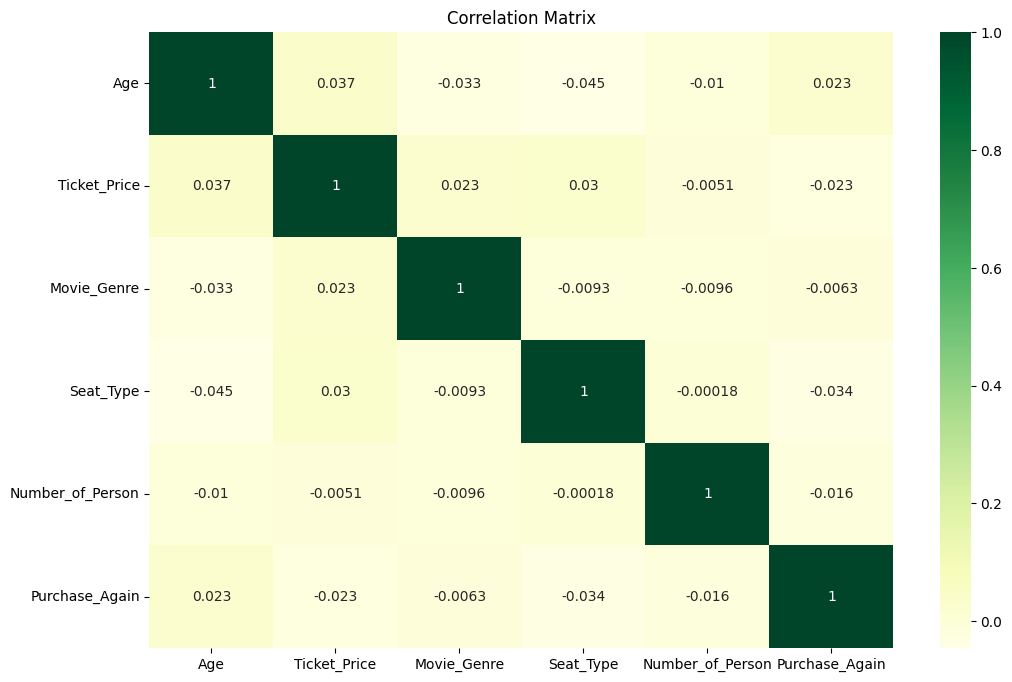

In [231]:
plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, cmap='YlGn')
plt.title('Correlation Matrix')
plt.show()

# **SVM**

In [232]:
X=df.drop(columns=['Purchase_Again'])
Y=df['Purchase_Again']

In [233]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [234]:
from sklearn.svm import SVC
model = SVC(kernel='linear', random_state=42)
model.fit(X_train, y_train)

SVC(kernel='linear', random_state=42)

In [235]:
y_pred = model.predict(X_test)
print(y_pred)

[1 0 1 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1
 0 1 0 0 0 1 0 1 0 0 1 0 0 0 1 0 1 0 1 0 0 1 0 1 0 0 0 0 0 1 1 0 1 1 1 0 1
 1 0 1 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 1 1 0 0 1 0 0 0 0 1 0 1 0
 1 0 1 1 1 0 0 1 0 1 0 0 0 1 1 0 1 1 1 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0
 0 1 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 1 0 1 0 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1
 0 0 0 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0 0 1 0 0 1 0 0 1 1 1 0 1 1 1 0 1 0
 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 0 0 1 1 1 0 1 0 0 1 1 0 0 1 0 0 0 0 0 1
 1 0 0 1 0 0 0 1 1 1 0 0 1 0 0 1 1 0 0 0 0 0 0 0 0 1 1 0 1]


In [236]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Re-generate predictions to match the current y_test
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Calculate precision
precision = precision_score(y_test, y_pred)
print("Precision:", precision)

# Calculate recall (sensitivity)
recall = recall_score(y_test, y_pred)
print("Recall (Sensitivity):", recall)

# Calculate F1-score
f1 = f1_score(y_test, y_pred)
print("F1-Score:", f1)

Accuracy: 0.4965277777777778
Precision: 0.5092592592592593
Recall (Sensitivity): 0.3741496598639456
F1-Score: 0.43137254901960786


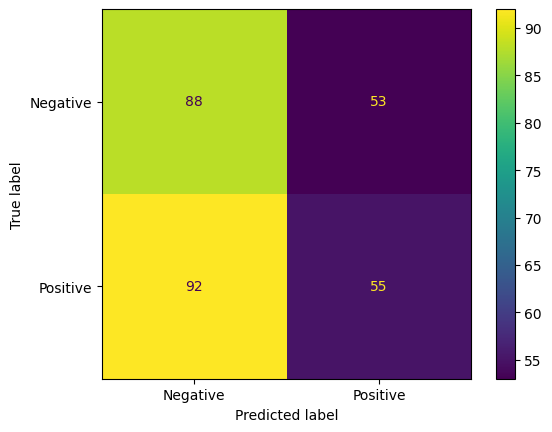

In [237]:
#confuison matrix
import matplotlib.pyplot as plt
from sklearn import metrics
confusion_matrix = metrics.confusion_matrix(y_test,y_pred)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = ['Negative', 'Positive'])
cm_display.plot()
plt.show()

# **DECISION TREE**



In [238]:
x=df.drop(columns=['Purchase_Again'])
y=df['Purchase_Again']

In [239]:
from sklearn.model_selection import train_test_split
X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(x, y, test_size=0.2, random_state=42)

In [240]:
from sklearn.tree import DecisionTreeClassifier
dtree = DecisionTreeClassifier()
dtree = dtree.fit(X_train, y_train)

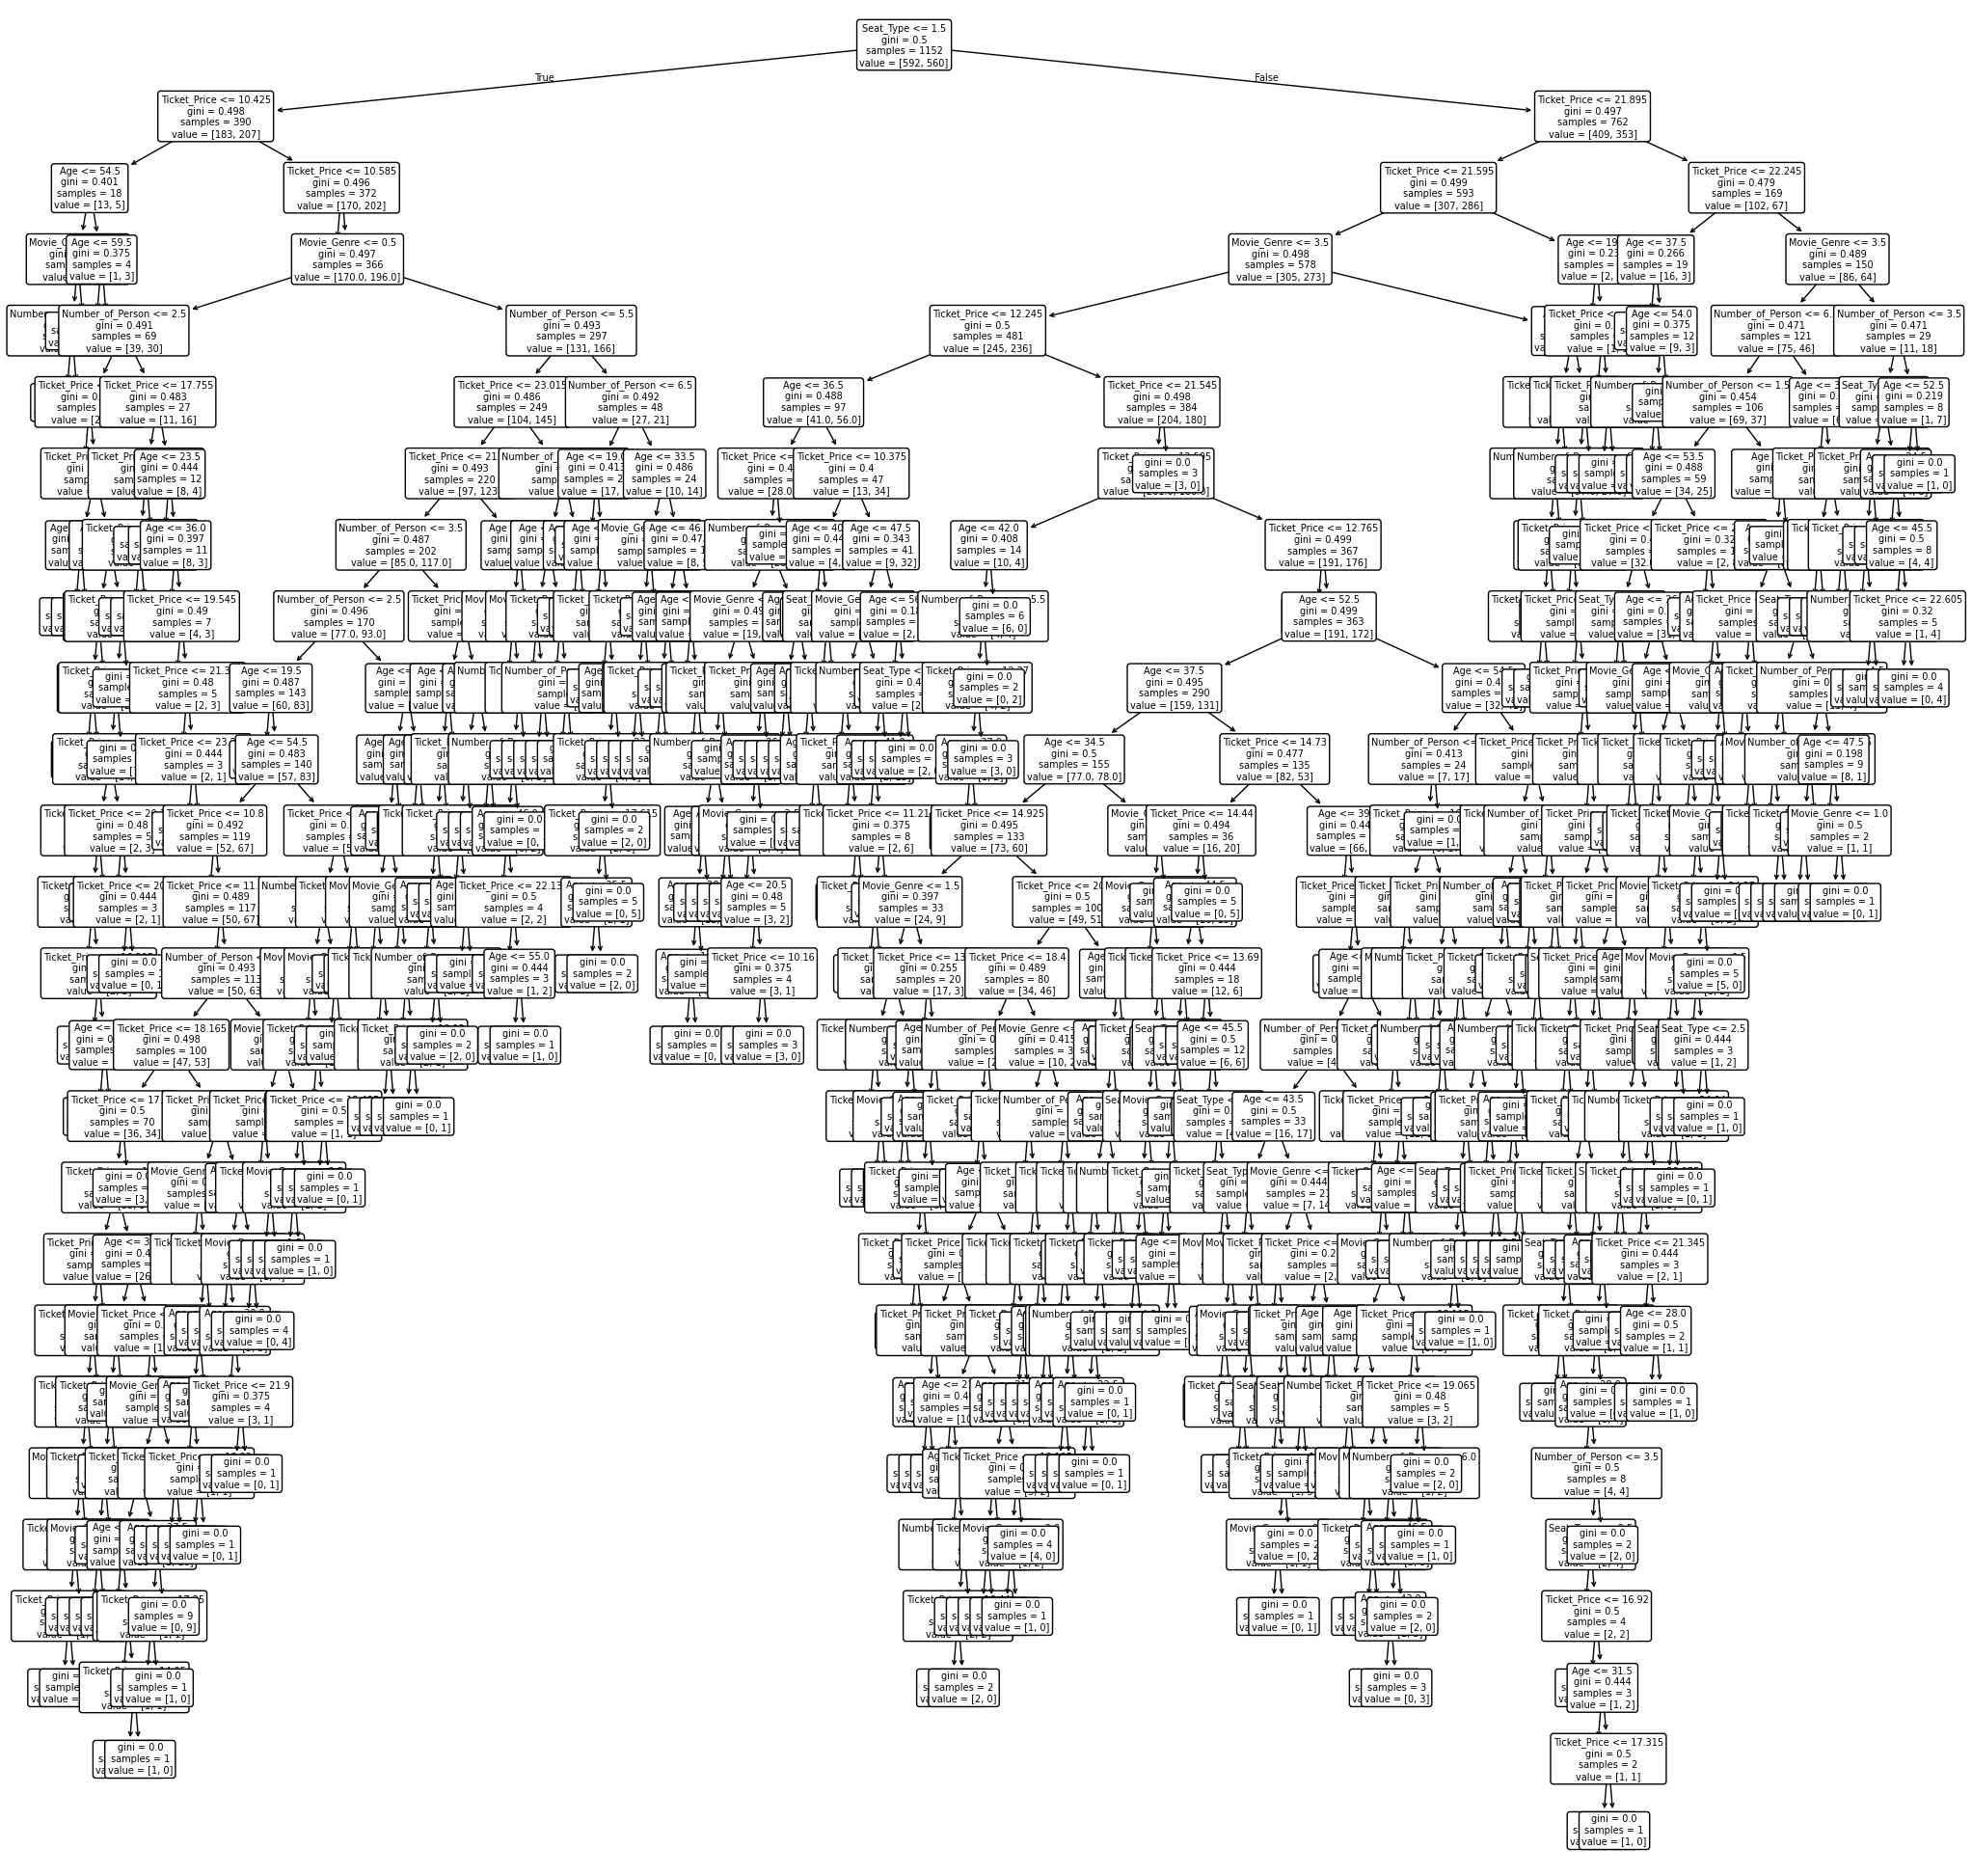

In [241]:
from sklearn import tree
feature_names = X.columns.tolist()
fig = plt.figure(figsize=(25, 25))
tree.plot_tree(dtree, feature_names=feature_names,rounded=True, fontsize=7)
plt.show()

In [242]:
y_pred_dt = dtree.predict(X_test_dt)
print(y_pred_dt)

[0 1 1 1 1 0 1 0 0 0 0 0 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 0 1 1 1 0 0 0 1 0 0
 0 0 1 1 1 0 0 1 1 1 0 0 0 0 0 0 1 0 1 1 0 1 0 0 1 1 1 0 1 0 0 0 1 1 0 0 0
 1 0 1 1 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 0 0 1 1 1 1 1 1 1 1 0 1 0 0 0 1 0
 1 1 1 0 1 1 1 0 1 0 0 0 0 1 1 0 0 1 1 0 1 0 1 1 0 1 0 1 0 1 0 0 1 1 1 0 0
 1 0 1 0 1 0 0 1 0 0 0 0 0 1 0 1 0 1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 1 0 0 1 1
 0 0 0 1 1 0 1 1 0 0 1 0 1 1 0 1 1 0 1 1 0 1 1 1 0 0 1 1 1 0 1 0 0 0 0 0 0
 1 1 0 1 0 1 1 0 0 1 0 0 0 1 0 1 1 1 0 1 1 0 0 0 1 1 1 0 1 1 1 0 0 0 1 1 1
 1 0 0 1 1 0 1 0 1 1 0 1 0 1 0 0 1 0 1 1 0 0 0 1 0 0 0 1 1]


In [243]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate accuracy
accuracy_dt = accuracy_score(y_test_dt, y_pred_dt)
print("Accuracy:", accuracy_dt)

# Calculate precision
precision_dt = precision_score(y_test_dt, y_pred_dt)
print("Precision:", precision_dt)

# Calculate recall (sensitivity)
recall_dt = recall_score(y_test_dt, y_pred_dt)
print("Recall (Sensitivity):", recall_dt)

# Calculate F1-score
f1_dt = f1_score(y_test_dt, y_pred_dt)
print("F1-Score:", f1_dt)

Accuracy: 0.4618055555555556
Precision: 0.47183098591549294
Recall (Sensitivity): 0.4557823129251701
F1-Score: 0.46366782006920415


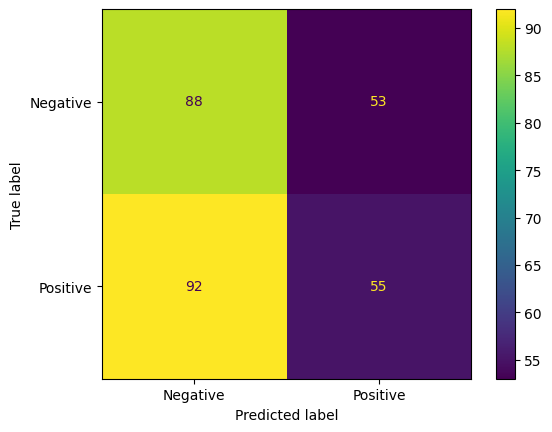

In [244]:
#confuison matrix
import matplotlib.pyplot as plt
from sklearn import metrics
confusion_matrix = metrics.confusion_matrix(y_test,y_pred)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = ['Negative', 'Positive'])
cm_display.plot()
plt.show()

# **RANDOM FOREST**

In [245]:
from sklearn.ensemble import RandomForestClassifier

In [246]:
y = df["Purchase_Again"]
X = df.drop("Purchase_Again", axis=1)

In [252]:
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(X, y, test_size=0.2, random_state=42)

In [251]:
# Train Random Forest model
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [253]:
y_pred_rf = rf.predict(X_test)
y_pred_rf

array([1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1,
       1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1,
       1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       0, 0])

In [255]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate accuracy
accuracy_rf = accuracy_score(y_test_rf, y_pred_rf)
print("Accuracy:", accuracy_rf)

# Calculate precision
precision_rf = precision_score(y_test_rf, y_pred_rf)
print("Precision:", precision_rf)

# Calculate recall (sensitivity)
recall_rf = recall_score(y_test_rf, y_pred_rf)
print("Recall (Sensitivity):", recall_rf)

# Calculate F1-score
f1_rf = f1_score(y_test_rf, y_pred_rf)
print("F1-Score:", f1_rf)

Accuracy: 0.5138888888888888
Precision: 0.5251798561151079
Recall (Sensitivity): 0.4965986394557823
F1-Score: 0.5104895104895105


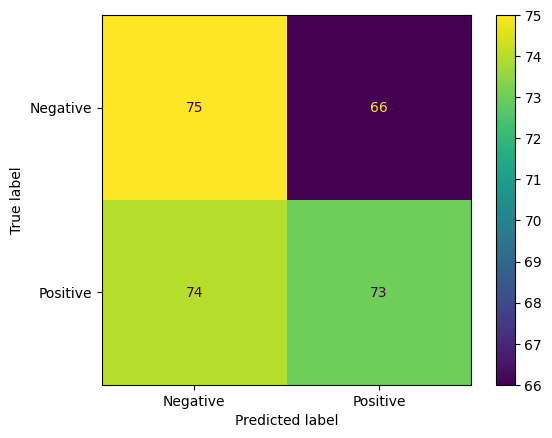

In [256]:
#confuison matrix
import matplotlib.pyplot as plt
from sklearn import metrics
confusion_matrix = metrics.confusion_matrix(y_test,y_pred)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = ['Negative', 'Positive'])
cm_display.plot()
plt.show()

# Create comparison table


In [257]:
# Create a dictionary to store the metrics
performance_metrics = {
    'SVM': {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    },
    'Decision Tree': {
        'Accuracy': accuracy_dt,
        'Precision': precision_dt,
        'Recall': recall_dt,
        'F1-Score': f1_dt
    },
    'Random Forest': {
        'Accuracy': accuracy_rf,
        'Precision': precision_rf,
        'Recall': recall_rf,
        'F1-Score': f1_rf
    }
}

# Create a pandas DataFrame from the dictionary
performance_df = pd.DataFrame.from_dict(performance_metrics, orient='index')

# Print the DataFrame
display(performance_df)

,Accuracy,Precision,Recall,F1-Score
SVM,0.496528,0.509259,0.374150,0.431373
Decision Tree,0.513889,0.471831,0.455782,0.463668
Random Forest,0.513889,0.525180,0.496599,0.510490


## Define parameter grids


In [261]:
# Define parameter grids for each model
param_grid_svm = {'C': [0.1, 1, 10, 100],
                  'gamma': [1, 0.1, 0.01, 0.001],
                  'kernel': ['linear', 'rbf']}

param_grid_dt = {'max_depth': [None, 10, 20, 30],
                 'min_samples_split': [2, 5, 10],
                 'min_samples_leaf': [1, 2, 4]}

param_grid_rf = {'n_estimators': [100, 200, 500],
                 'max_features': ['sqrt', 'log2'],
                 'max_depth': [10, 20, 30, None]}

print("SVM Parameter Grid:")
print(param_grid_svm)
print("\nDecision Tree Parameter Grid:")
print(param_grid_dt)
print("\nRandom Forest Parameter Grid:")
print(param_grid_rf)

SVM Parameter Grid:
{'C': [0.1, 1, 10, 100], 'gamma': [1, 0.1, 0.01, 0.001], 'kernel': ['linear', 'rbf']}

Decision Tree Parameter Grid:
{'max_depth': [None, 10, 20, 30], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}

Random Forest Parameter Grid:
{'n_estimators': [100, 200, 500], 'max_features': ['sqrt', 'log2'], 'max_depth': [10, 20, 30, None]}


## Apply gridsearchcv




In [262]:
from sklearn.model_selection import GridSearchCV

grid_search_svm = GridSearchCV(model, param_grid_svm, cv=5)
grid_search_svm.fit(X_train, y_train)
print("Best parameters for SVM:", grid_search_svm.best_params_)

grid_search_dt = GridSearchCV(dtree, param_grid_dt, cv=5)
grid_search_dt.fit(X_train, y_train)
print("Best parameters for Decision Tree:", grid_search_dt.best_params_)

grid_search_rf = GridSearchCV(rf, param_grid_rf, cv=5)
grid_search_rf.fit(X_train, y_train)
print("Best parameters for Random Forest:", grid_search_rf.best_params_)

Best parameters for SVM: {'C': 100, 'gamma': 1, 'kernel': 'linear'}
Best parameters for Decision Tree: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5}
Best parameters for Random Forest: {'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 100}


# Evaluate tuned models



In [265]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Get the best performing models
best_svm_model = grid_search_svm.best_estimator_
best_dt_model = grid_search_dt.best_estimator_
best_rf_model = grid_search_rf.best_estimator_

# Make predictions on the test set
y_pred_svm_tuned = best_svm_model.predict(X_test)
y_pred_dt_tuned = best_dt_model.predict(X_test)
y_pred_rf_tuned = best_rf_model.predict(X_test)

# Calculate metrics for each tuned model
accuracy_svm_tuned = accuracy_score(y_test, y_pred_svm_tuned)
precision_svm_tuned = precision_score(y_test, y_pred_svm_tuned)
recall_svm_tuned = recall_score(y_test, y_pred_svm_tuned)
f1_svm_tuned = f1_score(y_test, y_pred_svm_tuned)

accuracy_dt_tuned = accuracy_score(y_test, y_pred_dt_tuned)
precision_dt_tuned = precision_score(y_test, y_pred_dt_tuned)
recall_dt_tuned = recall_score(y_test, y_pred_dt_tuned)
f1_dt_tuned = f1_score(y_test, y_pred_dt_tuned)

accuracy_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)
precision_rf_tuned = precision_score(y_test, y_pred_rf_tuned)
recall_rf_tuned = recall_score(y_test, y_pred_rf_tuned)
f1_rf_tuned = f1_score(y_test, y_pred_rf_tuned)

# Print the calculated metrics
print("Tuned SVM Metrics:")
print("Accuracy:", accuracy_svm_tuned)
print("Precision:", precision_svm_tuned)
print("Recall:", recall_svm_tuned)
print("F1-Score:", f1_svm_tuned)

print("\nTuned Decision Tree Metrics:")
print("Accuracy:", accuracy_dt_tuned)
print("Precision:", precision_dt_tuned)
print("Recall:", recall_dt_tuned)
print("F1-Score:", f1_dt_tuned)

print("\nTuned Random Forest Metrics:")
print("Accuracy:", accuracy_rf_tuned)
print("Precision:", precision_rf_tuned)
print("Recall:", recall_rf_tuned)
print("F1-Score:", f1_rf_tuned)

Tuned SVM Metrics:
Accuracy: 0.4895833333333333
Precision: 0.5
Recall: 0.3673469387755102
F1-Score: 0.4235294117647059

Tuned Decision Tree Metrics:
Accuracy: 0.4583333333333333
Precision: 0.46153846153846156
Recall: 0.3673469387755102
F1-Score: 0.4090909090909091

Tuned Random Forest Metrics:
Accuracy: 0.4930555555555556
Precision: 0.5038167938931297
Recall: 0.4489795918367347
F1-Score: 0.4748201438848921


In [264]:
from sklearn.model_selection import RandomizedSearchCV

# Define parameter distributions (similar to grids for simplicity in this case)
param_dist_svm = param_grid_svm
param_dist_dt = param_grid_dt
param_dist_rf = param_grid_rf

# Apply RandomizedSearchCV
random_search_svm = RandomizedSearchCV(model, param_dist_svm, n_iter=10, cv=5, random_state=42)
random_search_svm.fit(X_train, y_train)
print("Best parameters for SVM (Randomized Search):", random_search_svm.best_params_)

random_search_dt = RandomizedSearchCV(dtree, param_dist_dt, n_iter=10, cv=5, random_state=42)
random_search_dt.fit(X_train, y_train)
print("Best parameters for Decision Tree (Randomized Search):", random_search_dt.best_params_)

random_search_rf = RandomizedSearchCV(rf, param_dist_rf, n_iter=10, cv=5, random_state=42)
random_search_rf.fit(X_train, y_train)
print("Best parameters for Random Forest (Randomized Search):", random_search_rf.best_params_)

Best parameters for SVM (Randomized Search): {'kernel': 'linear', 'gamma': 1, 'C': 100}
Best parameters for Decision Tree (Randomized Search): {'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 10}
Best parameters for Random Forest (Randomized Search): {'n_estimators': 100, 'max_features': 'log2', 'max_depth': 20}


In [266]:
# Get the best performing models from Randomized Search
best_svm_model_rs = random_search_svm.best_estimator_
best_dt_model_rs = random_search_dt.best_estimator_
best_rf_model_rs = random_search_rf.best_estimator_

# Make predictions on the test set
y_pred_svm_tuned_rs = best_svm_model_rs.predict(X_test)
y_pred_dt_tuned_rs = best_dt_model_rs.predict(X_test)
y_pred_rf_tuned_rs = best_rf_model_rs.predict(X_test)

# Calculate metrics for each tuned model
accuracy_svm_tuned_rs = accuracy_score(y_test, y_pred_svm_tuned_rs)
precision_svm_tuned_rs = precision_score(y_test, y_pred_svm_tuned_rs)
recall_svm_tuned_rs = recall_score(y_test, y_pred_svm_tuned_rs)
f1_svm_tuned_rs = f1_score(y_test, y_pred_svm_tuned_rs)

accuracy_dt_tuned_rs = accuracy_score(y_test, y_pred_dt_tuned_rs)
precision_dt_tuned_rs = precision_score(y_test, y_pred_dt_tuned_rs)
recall_dt_tuned_rs = recall_score(y_test, y_pred_dt_tuned_rs)
f1_dt_tuned_rs = f1_score(y_test, y_pred_dt_tuned_rs)

accuracy_rf_tuned_rs = accuracy_score(y_test, y_pred_rf_tuned_rs)
precision_rf_tuned_rs = precision_score(y_test, y_pred_rf_tuned_rs)
recall_rf_tuned_rs = recall_score(y_test, y_pred_rf_tuned_rs)
f1_rf_tuned_rs = f1_score(y_test, y_pred_rf_tuned_rs)

# Print the calculated metrics
print("Randomized Search Tuned SVM Metrics:")
print("Accuracy:", accuracy_svm_tuned_rs)
print("Precision:", precision_svm_tuned_rs)
print("Recall:", recall_svm_tuned_rs)
print("F1-Score:", f1_svm_tuned_rs)

print("\nRandomized Search Tuned Decision Tree Metrics:")
print("Accuracy:", accuracy_dt_tuned_rs)
print("Precision:", precision_dt_tuned_rs)
print("Recall:", recall_dt_tuned_rs)
print("F1-Score:", f1_dt_tuned_rs)

print("\nRandomized Search Tuned Random Forest Metrics:")
print("Accuracy:", accuracy_rf_tuned_rs)
print("Precision:", precision_rf_tuned_rs)
print("Recall:", recall_rf_tuned_rs)
print("F1-Score:", f1_rf_tuned_rs)

Randomized Search Tuned SVM Metrics:
Accuracy: 0.4895833333333333
Precision: 0.5
Recall: 0.3673469387755102
F1-Score: 0.4235294117647059

Randomized Search Tuned Decision Tree Metrics:
Accuracy: 0.4270833333333333
Precision: 0.4423076923076923
Recall: 0.46938775510204084
F1-Score: 0.45544554455445546

Randomized Search Tuned Random Forest Metrics:
Accuracy: 0.4930555555555556
Precision: 0.5038167938931297
Recall: 0.4489795918367347
F1-Score: 0.4748201438848921


In [267]:
# Add Randomized Search results to the performance metrics dictionary
performance_metrics['SVM_RandomizedSearch'] = {
    'Accuracy': accuracy_svm_tuned_rs,
    'Precision': precision_svm_tuned_rs,
    'Recall': recall_svm_tuned_rs,
    'F1-Score': f1_svm_tuned_rs
}

performance_metrics['Decision Tree_RandomizedSearch'] = {
    'Accuracy': accuracy_dt_tuned_rs,
    'Precision': precision_dt_tuned_rs,
    'Recall': recall_dt_tuned_rs,
    'F1-Score': f1_dt_tuned_rs
}

performance_metrics['Random Forest_RandomizedSearch'] = {
    'Accuracy': accuracy_rf_tuned_rs,
    'Precision': precision_rf_tuned_rs,
    'Recall': recall_rf_tuned_rs,
    'F1-Score': f1_rf_tuned_rs
}

# Create a pandas DataFrame from the updated dictionary
performance_df_tuned = pd.DataFrame.from_dict(performance_metrics, orient='index')

# Print the DataFrame
display(performance_df_tuned)

,Accuracy,Precision,Recall,F1-Score
SVM,0.496528,0.509259,0.374150,0.431373
Decision Tree,0.513889,0.471831,0.455782,0.463668
Random Forest,0.513889,0.525180,0.496599,0.510490
SVM_RandomizedSearch,0.489583,0.500000,0.367347,0.423529
Decision Tree_RandomizedSearch,0.427083,0.442308,0.469388,0.455446
Random Forest_RandomizedSearch,0.493056,0.503817,0.448980,0.474820


# Report best performing model


In [268]:
print("Performance Metrics of all models:")
display(performance_df_tuned)

# Identify the best performing model.
# For this classification task, a balanced approach considering Precision, Recall, and F1-Score is important.
# F1-Score is a good metric to consider as it is the harmonic mean of Precision and Recall.
# Let's find the model with the highest F1-Score.

best_model_name = performance_df_tuned['F1-Score'].idxmax()
best_model_metrics = performance_df_tuned.loc[best_model_name]

print(f"\nBased on F1-Score, the best performing model is: {best_model_name}")
print("Metrics for the best performing model:")
print(best_model_metrics)

# Justify the choice
print(f"\nJustification for choosing {best_model_name}:")
print(f"The {best_model_name} model achieved the highest F1-Score ({best_model_metrics['F1-Score']:.4f}) among all tested models.")
print("F1-Score provides a balance between Precision and Recall, which is often desirable in classification tasks.")
print(f"While other models might have higher values in individual metrics (e.g., Precision or Recall), the {best_model_name} model demonstrates the best overall performance considering both false positives and false negatives as indicated by the F1-Score.")

Performance Metrics of all models:


,Accuracy,Precision,Recall,F1-Score
SVM,0.496528,0.509259,0.374150,0.431373
Decision Tree,0.513889,0.471831,0.455782,0.463668
Random Forest,0.513889,0.525180,0.496599,0.510490
SVM_RandomizedSearch,0.489583,0.500000,0.367347,0.423529
Decision Tree_RandomizedSearch,0.427083,0.442308,0.469388,0.455446
Random Forest_RandomizedSearch,0.493056,0.503817,0.448980,0.474820



Based on F1-Score, the best performing model is: Random Forest
Metrics for the best performing model:
Accuracy     0.513889
Precision    0.525180
Recall       0.496599
F1-Score     0.510490
Name: Random Forest, dtype: float64

Justification for choosing Random Forest:
The Random Forest model achieved the highest F1-Score (0.5105) among all tested models.
F1-Score provides a balance between Precision and Recall, which is often desirable in classification tasks.
While other models might have higher values in individual metrics (e.g., Precision or Recall), the Random Forest model demonstrates the best overall performance considering both false positives and false negatives as indicated by the F1-Score.
